In [1]:
# libraries — run after 02b_varying_wind_sim
import base64
import io
import json
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image


In [2]:
# globals; simulation settings are read from 02b outputs, not from a newer 01 configuration
ROOT = Path.cwd().resolve()
if ROOT.name == 'src':
    ROOT = ROOT.parent.parent
IN = ROOT/'c_analyze/input/upstream/varying_wind'
OUT = ROOT/'c_analyze/output/varying_wind'
OUT.mkdir(parents=True,exist_ok=True)
cfg = json.loads((IN/'config.json').read_text())
settings = json.loads((IN/'varying_wind_settings.json').read_text())
SEED = cfg['seed']
rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid',context='notebook',palette='colorblind')
colors = sns.color_palette('colorblind',4)
styles = ['-','--',':','-.']
markers = ['o','s','^','D']
plt.rcParams.update({'figure.dpi':120,'savefig.dpi':180,'axes.spines.top':False,'axes.spines.right':False})


In [3]:
# load only this experiment's outputs; no old weather_demo file is used
design = pd.read_csv(IN/'design.csv')
keys = design['condition'].tolist()
labels = dict(zip(keys,design['label']))
experiments = {key:dict(np.load(IN/f'{key}.npz')) for key in keys}
blocks = pd.read_csv(IN/'block_lengths.csv')
audit = pd.read_csv(IN/'simulation_audit.csv')
x = np.arange(cfg['nx'])
y = np.arange(cfg['ny'])-cfg['source_y']
pd.read_csv(IN/'methods.csv')


,item,specification
0,question,Does variation in block length change exposure...
1,reference,Fixed L=16 is the matched-mean reference; L=1 ...
2,variable law,"Each generated block has marginal Uniform{4,....."
3,balance,Durations are paired around 16; each sign rece...
4,dependence,Balancing couples block lengths within each fi...
5,matched wind order,Fixed L=16 and variable case share sign order ...
6,wind runs,Adjacent blocks can share a sign; actual unint...
7,transport,"Original east/NE/SE CA; same source, wind bias..."
8,initialization,"Half clean, half established; main statistics ..."
9,scope,"Illustrative duration distribution, not calibr..."


In [4]:
# distinguish constructed blocks from uninterrupted wind runs, which can span several blocks
wind_rows,acf_rows = [],[]
for key,exp in experiments.items():
    wind = exp['wind'][:,cfg['burn_in']:].astype(float)
    for trial,w in enumerate(wind):
        changes = np.flatnonzero(w != np.roll(w,1))
        durations = (np.roll(changes,-1)-changes) % len(w)
        wind_rows.append({'condition':key,'trial':trial,'positive_fraction':(w==1).mean(),
            'circular_direction_changes':len(changes),'mean_wind_run':durations.mean(),
            'sd_wind_run':durations.std()})
    for lag in range(settings['wind_max_lag']+1):
        if lag == 0:
            acf = np.ones(cfg['n_trials'])
        else:
            a,b = wind[:,:-lag],wind[:,lag:]
            a = a-a.mean(axis=1,keepdims=True)
            b = b-b.mean(axis=1,keepdims=True)
            acf = (a*b).sum(axis=1)/np.sqrt((a*a).sum(axis=1)*(b*b).sum(axis=1))
        acf_rows.extend({'condition':key,'trial':trial,'lag':lag,'correlation':value}
            for trial,value in enumerate(acf))
wind_metrics = pd.DataFrame(wind_rows)
acf = pd.DataFrame(acf_rows)
wind_metrics.to_csv(OUT/'wind_metrics.csv',index=False)
acf.to_csv(OUT/'wind_autocorrelation.csv',index=False)
block_summary = blocks.groupby('condition',sort=False)['length'].agg(mean_block='mean',sd_block=lambda z:z.std(ddof=0))
wind_summary = wind_metrics.groupby('condition',sort=False).agg(
    positive_fraction=('positive_fraction','mean'),mean_wind_run=('mean_wind_run','mean'),
    mean_within_trial_run_sd=('sd_wind_run','mean'))
wind_summary = block_summary.join(wind_summary).reindex(keys)
wind_summary.to_csv(OUT/'wind_summary.csv')
wind_summary.round(3)


,mean_block,sd_block,positive_fraction,mean_wind_run,mean_within_trial_run_sd
condition,,,,,
fixed_1,1.0,0.000,0.5,1.999,1.409
fixed_16,16.0,0.000,0.5,31.955,21.746
fixed_32,32.0,0.000,0.5,63.566,39.383
variable_16,16.0,7.263,0.5,31.955,23.734


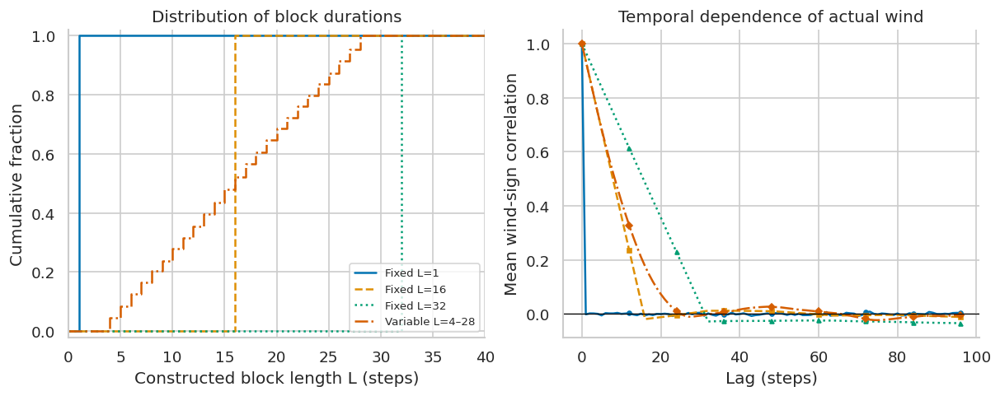

In [5]:
# wind diagnostics: variable block lengths share a mean with fixed L=16, not a fixed duration
fig,axes = plt.subplots(1,2,figsize=(10,3.9),constrained_layout=True)
for j,key in enumerate(keys):
    values,counts = np.unique(blocks.loc[blocks['condition'].eq(key),'length'],return_counts=True)
    axes[0].step(np.r_[0,values,40],np.r_[0,counts.cumsum()/counts.sum(),1],where='post',
        color=colors[j],ls=styles[j],label=labels[key])
    part = acf.loc[acf['condition'].eq(key)].groupby('lag')['correlation'].mean()
    axes[1].plot(part.index,part.values,color=colors[j],ls=styles[j],marker=markers[j],
        markevery=12,ms=3,label=labels[key])
axes[0].set(xlabel='Constructed block length L (steps)',ylabel='Cumulative fraction',
    title='Distribution of block durations',xlim=(0,40),ylim=(-.02,1.02))
axes[1].axhline(0,color='black',lw=.7)
axes[1].set(xlabel='Lag (steps)',ylabel='Mean wind-sign correlation',title='Temporal dependence of actual wind')
axes[0].legend(fontsize=8,loc='lower right')
fig.savefig(OUT/'01_wind_diagnostics.png')
plt.show()


In [6]:
# exposure episodes; endpoints touching the observation window are excluded from duration estimates
def episode_lengths(values,threshold):
    above = values > threshold
    edges = np.diff(np.r_[False,above,False].astype(np.int8))
    starts = np.flatnonzero(edges==1)
    stops = np.flatnonzero(edges==-1)
    complete = (starts>0)&(stops<len(values))
    return stops[complete]-starts[complete],int((~complete).sum())

trial_rows = []
for key,exp in experiments.items():
    measured = exp['trace'][:,cfg['burn_in']:]
    for trial in range(cfg['n_trials']):
        for j,offset in enumerate(cfg['receptor_offsets']):
            values = measured[trial,:,j]
            lengths,censored = episode_lengths(values,cfg['exposure_threshold'])
            trial_rows.append({'condition':key,'trial':trial,'initial':exp['initial'][trial],
                'receptor_y':offset,'mean_concentration':values.mean(),
                'exposure_fraction':(values>cfg['exposure_threshold']).mean(),
                'episodes':len(lengths),'duration_sum':lengths.sum(),'censored_episodes':censored})
trials = pd.DataFrame(trial_rows)
trials.to_csv(OUT/'trial_metrics.csv',index=False)


In [7]:
# confidence intervals resample whole trials within initialization groups
# duration is total complete-episode time / total number of complete episodes
def boot_metrics(group,rng,draws):
    samples = []
    for _,part in group.groupby('initial',sort=False):
        a = part[['mean_concentration','exposure_fraction','episodes','duration_sum']].to_numpy()
        index = rng.integers(0,len(a),size=(draws,len(a)))
        samples.append(a[index].sum(axis=1))
    totals = np.sum(samples,axis=0)
    duration = np.divide(totals[:,3],totals[:,2],out=np.full(draws,np.nan),where=totals[:,2]>0)
    return np.column_stack([totals[:,0]/len(group),totals[:,1]/len(group),duration])

summary_rows = []
for (key,offset),group in trials.groupby(['condition','receptor_y'],sort=False):
    boot = boot_metrics(group,rng,settings['bootstrap_draws'])
    n = group['episodes'].sum()
    point = [group['mean_concentration'].mean(),group['exposure_fraction'].mean(),
        group['duration_sum'].sum()/n if n else np.nan]
    row = {'condition':key,'receptor_y':offset,'trials':len(group),'episodes':n,
        'censored_episodes':group['censored_episodes'].sum()}
    for i,name in enumerate(['concentration','exposure','duration']):
        row.update({name:point[i],name+'_lo':np.nanquantile(boot[:,i],.025),
            name+'_hi':np.nanquantile(boot[:,i],.975)})
    summary_rows.append(row)
summary = pd.DataFrame(summary_rows)
summary.to_csv(OUT/'exposure_summary.csv',index=False)
summary.round(3)


,condition,receptor_y,trials,episodes,censored_episodes,concentration,concentration_lo,concentration_hi,exposure,exposure_lo,exposure_hi,duration,duration_lo,duration_hi
0,fixed_1,-12,64,14,0,0.290,0.281,0.299,0.000,0.000,0.001,1.857,1.333,2.286
1,fixed_1,0,64,1143,126,6.635,6.597,6.672,0.966,0.962,0.971,40.899,36.521,45.997
2,fixed_1,12,64,13,0,0.289,0.281,0.298,0.000,0.000,0.001,1.615,1.000,2.800
3,fixed_16,-12,64,434,17,1.505,1.451,1.558,0.150,0.139,0.161,21.906,20.152,23.820
4,fixed_16,0,64,7464,46,3.352,3.251,3.455,0.408,0.393,0.423,3.552,3.440,3.676
5,fixed_16,12,64,416,32,1.508,1.454,1.558,0.148,0.137,0.158,21.822,20.009,23.810
6,fixed_32,-12,64,481,28,2.045,1.993,2.100,0.271,0.261,0.282,35.000,32.559,37.602
7,fixed_32,0,64,3503,39,2.392,2.285,2.502,0.301,0.286,0.316,5.550,5.413,5.695
8,fixed_32,12,64,477,40,2.038,1.987,2.090,0.270,0.260,0.281,33.702,30.759,37.015
9,variable_16,-12,64,905,21,1.702,1.646,1.756,0.207,0.196,0.218,14.589,13.125,16.249


In [8]:
# paired comparison: variable minus fixed L=16; resample matched trial IDs in each initial stratum
contrast_rows = []
for offset in cfg['receptor_offsets']:
    reference = trials.loc[trials['condition'].eq('fixed_16')&trials['receptor_y'].eq(offset)].sort_values('trial')
    variable = trials.loc[trials['condition'].eq('variable_16')&trials['receptor_y'].eq(offset)].sort_values('trial')
    totals = []
    for initial in ['clean','established']:
        ref = reference.loc[reference['initial'].eq(initial),['mean_concentration','exposure_fraction','episodes','duration_sum']].to_numpy()
        var = variable.loc[variable['initial'].eq(initial),['mean_concentration','exposure_fraction','episodes','duration_sum']].to_numpy()
        index = rng.integers(0,len(ref),size=(settings['bootstrap_draws'],len(ref)))
        totals.append(np.stack([ref[index].sum(axis=1),var[index].sum(axis=1)],axis=1))
    totals = np.sum(totals,axis=0)
    concentration = totals[:,:,0]/cfg['n_trials']
    exposure = totals[:,:,1]/cfg['n_trials']
    duration = np.divide(totals[:,:,3],totals[:,:,2],out=np.full_like(totals[:,:,3],np.nan),where=totals[:,:,2]>0)
    ref_point = summary.loc[summary['condition'].eq('fixed_16')&summary['receptor_y'].eq(offset)].iloc[0]
    var_point = summary.loc[summary['condition'].eq('variable_16')&summary['receptor_y'].eq(offset)].iloc[0]
    for name,values in [('concentration',concentration),('exposure',exposure),('duration',duration)]:
        difference = values[:,1]-values[:,0]
        contrast_rows.append({'receptor_y':offset,'metric':name,'variable_minus_fixed16':var_point[name]-ref_point[name],
            'lo':np.nanquantile(difference,.025),'hi':np.nanquantile(difference,.975)})
contrasts = pd.DataFrame(contrast_rows)
contrasts.to_csv(OUT/'variable_vs_fixed16.csv',index=False)
contrasts.round(4)


,receptor_y,metric,variable_minus_fixed16,lo,hi
0,-12,concentration,0.1966,0.1507,0.2428
1,-12,exposure,0.0566,0.0478,0.0651
2,-12,duration,-7.3166,-9.3363,-5.4104
3,0,concentration,-0.1252,-0.2082,-0.0368
4,0,exposure,-0.0054,-0.0198,0.0104
5,0,duration,7.3384,6.7944,7.9429
6,12,concentration,0.2058,0.1652,0.2461
7,12,exposure,0.0631,0.0557,0.0709
8,12,duration,-7.9418,-9.9997,-5.9201


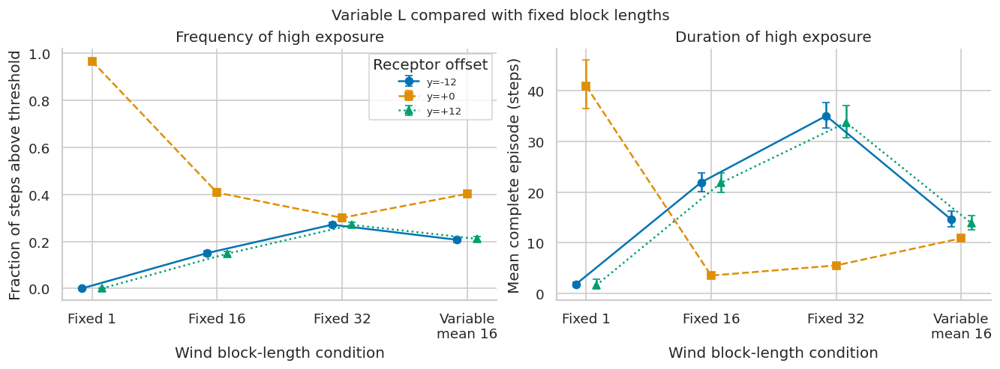

In [9]:
# exposure frequency and complete episode duration; shared definitions across all conditions
fig,axes = plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
positions = np.arange(len(keys))
for j,offset in enumerate(cfg['receptor_offsets']):
    part = summary.loc[summary['receptor_y'].eq(offset)].set_index('condition').loc[keys]
    xp = positions+(j-1)*.08
    for ax,name in zip(axes,['exposure','duration']):
        ax.errorbar(xp,part[name],yerr=np.vstack([part[name]-part[name+'_lo'],part[name+'_hi']-part[name]]),
            color=colors[j],marker=markers[j],ls=styles[j],capsize=3,label=f'y={offset:+d}')
        ax.set_xticks(positions,['Fixed 1','Fixed 16','Fixed 32','Variable\nmean 16'])
        ax.set_xlabel('Wind block-length condition')
axes[0].set(ylabel='Fraction of steps above threshold',title='Frequency of high exposure')
axes[1].set(ylabel='Mean complete episode (steps)',title='Duration of high exposure')
axes[0].legend(title='Receptor offset',fontsize=8)
fig.suptitle('Variable L compared with fixed block lengths',fontsize=12)
fig.savefig(OUT/'02_exposure_results.png')
plt.show()


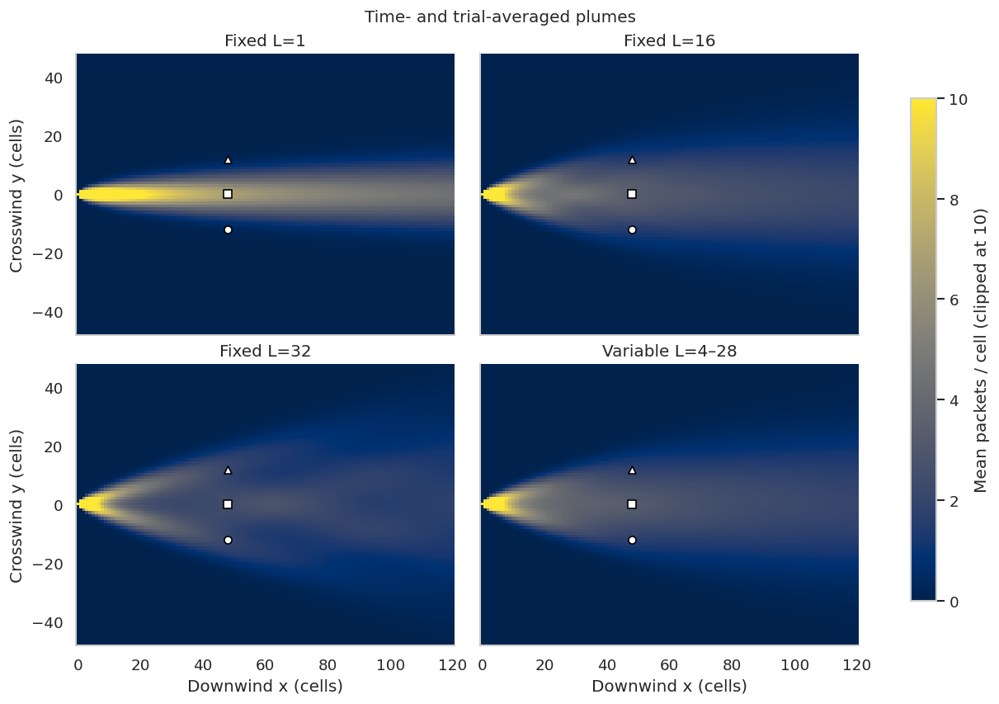

In [10]:
# mean plume maps; full downwind extent, common crosswind window and linear color scale
halfwidth = min(settings['display_halfwidth'],int(min(-y[0],y[-1])))
fig,axes = plt.subplots(2,2,figsize=(10,7),constrained_layout=True,sharex=True,sharey=True)
for ax,key in zip(axes.flat,keys):
    mean = experiments[key]['mean_grid'].mean(axis=0)
    image = ax.imshow(mean.T,origin='lower',extent=(-.5,x[-1]+.5,y[0]-.5,y[-1]+.5),
        aspect='auto',cmap='cividis',vmin=0,vmax=10)
    for j,offset in enumerate(cfg['receptor_offsets']):
        ax.scatter(cfg['receptor_x'],offset,marker=markers[j],s=30,c='white',edgecolors='black')
    ax.set(title=labels[key],ylim=(-halfwidth,halfwidth))
    ax.grid(False)
for ax in axes[-1]:
    ax.set_xlabel('Downwind x (cells)')
for ax in axes[:,0]:
    ax.set_ylabel('Crosswind y (cells)')
fig.colorbar(image,ax=axes,label='Mean packets / cell (clipped at 10)',shrink=.85)
fig.suptitle('Time- and trial-averaged plumes',fontsize=12)
fig.savefig(OUT/'03_mean_plumes.png')
plt.show()


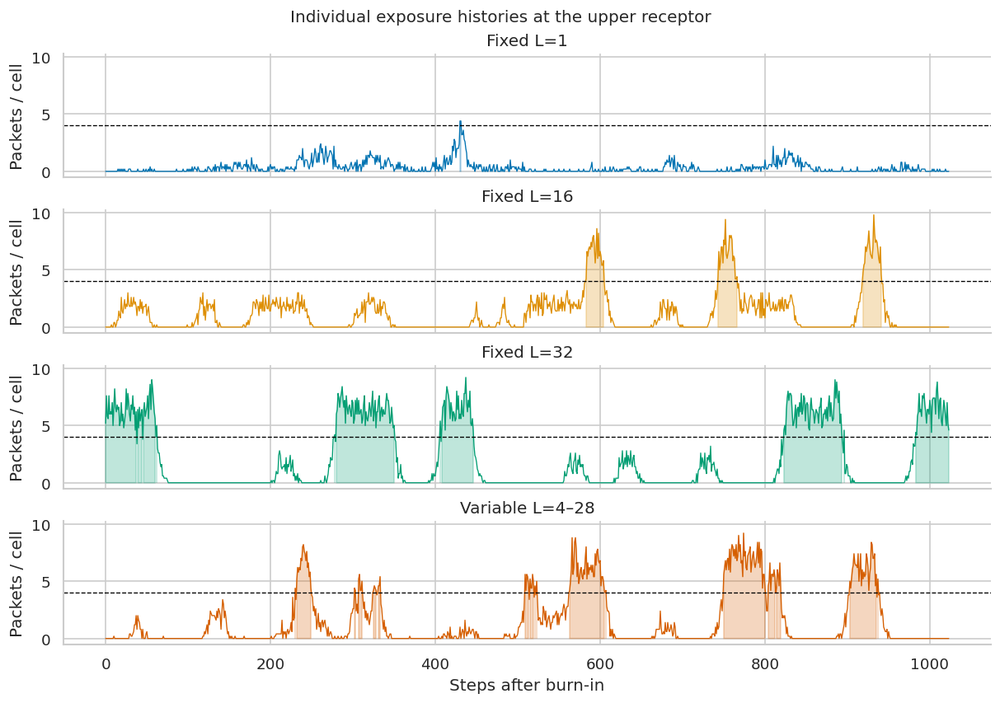

In [11]:
# one clean-air trial per condition; after burn-in, receptor y=+12
fig,axes = plt.subplots(4,1,figsize=(10,7),constrained_layout=True,sharex=True,sharey=True)
receptor = cfg['receptor_offsets'].index(12)
times = np.arange(cfg['n_steps'])
for j,(ax,key) in enumerate(zip(axes,keys)):
    values = experiments[key]['trace'][0,cfg['burn_in']:,receptor]
    ax.plot(times,values,color=colors[j],lw=.8)
    ax.axhline(cfg['exposure_threshold'],color='black',ls='--',lw=.8)
    ax.fill_between(times,0,values,where=values>cfg['exposure_threshold'],color=colors[j],alpha=.25)
    ax.set(title=labels[key],ylabel='Packets / cell')
axes[-1].set_xlabel('Steps after burn-in')
fig.suptitle('Individual exposure histories at the upper receptor',fontsize=12)
fig.savefig(OUT/'04_exposure_histories.png')
plt.show()


In [12]:
# sensitivity to illustrative exposure thresholds; reuse the completed simulations
sensitivity_rows = []
for key,exp in experiments.items():
    measured = exp['trace'][:,cfg['burn_in']:]
    for threshold in [2.,4.,6.]:
        for j,offset in enumerate(cfg['receptor_offsets']):
            sensitivity_rows.append({'condition':key,'receptor_y':offset,'threshold':threshold,
                'exposure_fraction':(measured[:,:,j]>threshold).mean()})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(OUT/'threshold_sensitivity.csv',index=False)
sensitivity.loc[sensitivity['receptor_y'].eq(12)].pivot(index='condition',columns='threshold',values='exposure_fraction').reindex(keys).round(3)


threshold,2.0,4.0,6.0
condition,,,
fixed_1,0.009,0.000,0.000
fixed_16,0.243,0.148,0.090
fixed_32,0.324,0.270,0.159
variable_16,0.281,0.211,0.120


In [13]:
# matched controls: equal sign frequencies, mean block duration, and circular direction-change count
matched = wind_metrics.loc[wind_metrics['condition'].isin(['fixed_16','variable_16'])]
flip_counts = matched.pivot(index='trial',columns='condition',values='circular_direction_changes')
controls = pd.DataFrame([
    ['positive wind fraction in every trial',wind_metrics['positive_fraction'].min(),wind_metrics['positive_fraction'].max()],
    ['mean block, fixed 16 vs variable',wind_summary.loc['fixed_16','mean_block'],wind_summary.loc['variable_16','mean_block']],
    ['maximum paired direction-change difference',0,(flip_counts['fixed_16']-flip_counts['variable_16']).abs().max()],
    ['maximum packet balance error',0,audit['max_mass_error'].max()],
    ['actual snapshot count',len(experiments[keys[0]]['frame_steps']),len(experiments[keys[-1]]['frame_steps'])]
],columns=['control','reference_or_min','observed_or_max'])
controls.to_csv(OUT/'matched_controls.csv',index=False)
controls


,control,reference_or_min,observed_or_max
0,positive wind fraction in every trial,0.5,0.5
1,"mean block, fixed 16 vs variable",16.0,16.0
2,maximum paired direction-change difference,0.0,0.0
3,maximum packet balance error,0.0,0.0
4,actual snapshot count,144.0,144.0



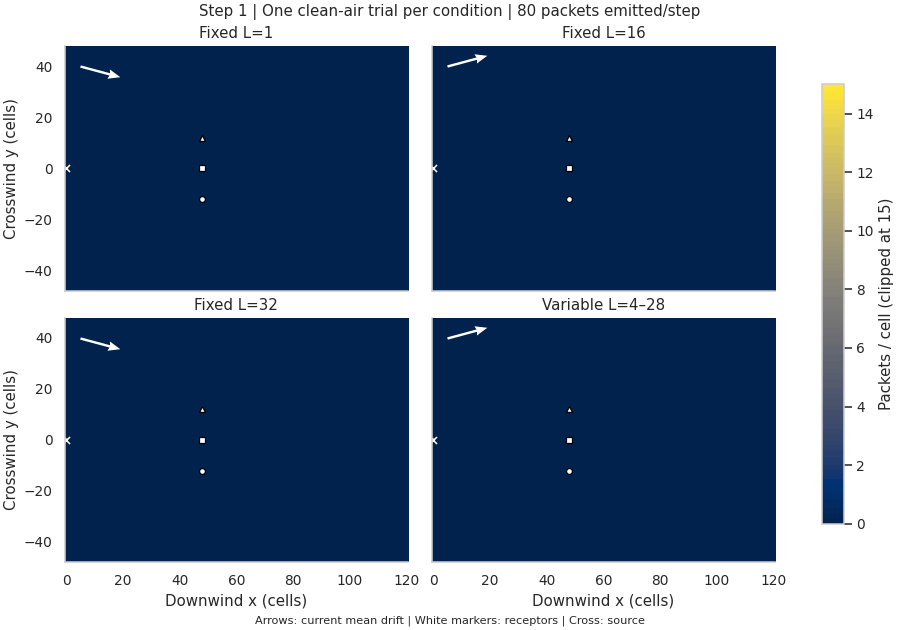

In [14]:
# GIF uses actual stored times/counts, not requested demo_frames; same transport in every panel
frame_steps = experiments[keys[0]]['frame_steps']
extent = (-.5,x[-1]+.5,y[0]-.5,y[-1]+.5)
fig,axes = plt.subplots(2,2,figsize=(10,7),dpi=90,constrained_layout=True,sharex=True,sharey=True)
artists,arrows = [],[]
for ax,key in zip(axes.flat,keys):
    image = ax.imshow(experiments[key]['frames'][0].T,origin='lower',extent=extent,
        aspect='auto',cmap='cividis',vmin=0,vmax=15)
    arrow = ax.quiver(5,halfwidth-8,14,0,angles='xy',scale_units='xy',scale=1,
        color='white',width=.007,headwidth=4,headlength=5)
    ax.scatter(0,0,marker='x',s=32,c='white',linewidths=1.2)
    for j,offset in enumerate(cfg['receptor_offsets']):
        ax.scatter(cfg['receptor_x'],offset,marker=markers[j],s=22,c='white',edgecolors='black')
    ax.set(title=labels[key],xlim=(-.5,x[-1]+.5),ylim=(-halfwidth,halfwidth))
    ax.grid(False)
    artists.append(image)
    arrows.append(arrow)
for ax in axes[-1]:
    ax.set_xlabel('Downwind x (cells)')
for ax in axes[:,0]:
    ax.set_ylabel('Crosswind y (cells)')
fig.colorbar(artists[0],ax=axes,label='Packets / cell (clipped at 15)',shrink=.85)
title = fig.suptitle('One initially clean trial per condition',fontsize=12)
fig.supxlabel('Arrows: current mean drift | White markers: receptors | Cross: source',fontsize=9)
fig.canvas.draw()
fig.set_layout_engine(None)
gif_frames = []
for frame,step in enumerate(frame_steps):
    for image,arrow,key in zip(artists,arrows,keys):
        image.set_data(experiments[key]['frames'][frame].T)
        sign = experiments[key]['wind'][0,int(step)-1]
        arrow.set_UVC(14,14*cfg['wind_bias']*sign)
    title.set_text(f'Step {step} | One clean-air trial per condition | {cfg["packets_per_step"]} packets emitted/step')
    fig.canvas.draw()
    gif_frames.append(Image.fromarray(np.asarray(fig.canvas.buffer_rgba())[:,:,:3].copy()))
    if frame == len(frame_steps)-1:
        fig.savefig(OUT/'05_variable_wind_snapshot.png',dpi=180)
plt.close(fig)
gif_path = OUT/'variable_wind_comparison.gif'
gif_frames[0].save(gif_path,save_all=True,append_images=gif_frames[1:],
    duration=round(1000/settings['gif_fps']),loop=0)
encoded = base64.b64encode(gif_path.read_bytes()).decode()
display({'text/html':f'<img alt="Fixed L=1,16,32 and variable blocks with mean 16" src="data:image/gif;base64,{encoded}">'},raw=True)


In [15]:
# interpretation guide; compare variable to fixed 16 before comparing to fast/slow references
notes = pd.DataFrame([
    ['primary comparison','Variable block lengths versus fixed L=16, holding mean block length at 16'],
    ['matched controls','Same emissions, transport probabilities given wind, mean duration, sign frequencies, and paired sign order'],
    ['actual runs','L describes constructed blocks; uninterrupted direction episodes may join several same-sign blocks'],
    ['finite balancing','Duration pairs and sign-specific histogram matching introduce dependence; this is not iid weather'],
    ['primary effect table','variable_vs_fixed16.csv gives paired trial-bootstrap differences and 95% intervals'],
    ['interval crossing zero','The current trials do not resolve the sign of that contrast; avoid claiming an established increase/decrease'],
    ['replication','Exposure figures summarize all trials; histories and GIF show one clean-air trial per condition'],
    ['duration censoring','Window-touching episodes are excluded; rare events can give unstable duration estimates'],
    ['units','Cells, steps, and packets; no physical concentration or health calibration'],
    ['GIF timing',f'{len(frame_steps)} stored snapshots, every {cfg["frame_interval"]} steps; last shown step {frame_steps[-1]}'],
    ['uncertainty settings',f'{settings["bootstrap_draws"]} bootstrap resamples for this new analysis'],
    ['files and run order','01_import -> 02b_varying_wind_sim -> 03b_varying_wind_analyze; outputs are under varying_wind/']
],columns=['item','interpretation'])
notes.to_csv(OUT/'interpretation.csv',index=False)
notes


,item,interpretation
0,primary comparison,"Variable block lengths versus fixed L=16, hold..."
1,matched controls,"Same emissions, transport probabilities given ..."
2,actual runs,L describes constructed blocks; uninterrupted ...
3,finite balancing,Duration pairs and sign-specific histogram mat...
4,primary effect table,variable_vs_fixed16.csv gives paired trial-boo...
5,interval crossing zero,The current trials do not resolve the sign of ...
6,replication,Exposure figures summarize all trials; histori...
7,duration censoring,Window-touching episodes are excluded; rare ev...
8,units,"Cells, steps, and packets; no physical concent..."
9,GIF timing,"144 stored snapshots, every 8 steps; last show..."
